# 종합실습1

## 인도 중고차 가격 예측 프로젝트

이 노트북은 Google Colab에서 실행하는 것을 기준으로 작성되었습니다.

분석 목표는 인도 중고차 데이터의 `Price`를 예측하는 것입니다. 주요 흐름은 다음과 같습니다.

1. 데이터 특성 확인 및 1차 정제
2. 결측치, 이상치, 파생변수 처리
3. 그래프 분석 및 통계적 가설검정
4. 선형 회귀와 랜덤 포레스트 모델링 성능 비교

현재 연도는 `2026년`으로 계산합니다.

## 0. 기본 라이브러리 및 환경 설정

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

import warnings
warnings.filterwarnings("ignore")

CURRENT_YEAR = 2026
RANDOM_STATE = 42

In [2]:
# Colab 한글 폰트 설정
# 폰트가 바로 적용되지 않으면 런타임을 재시작한 뒤 다시 실행하세요.
!apt-get -qq install fonts-nanum

import matplotlib.font_manager as fm

font_path = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"
fm.fontManager.addfont(font_path)
plt.rc("font", family="NanumGothic")
plt.rcParams["axes.unicode_minus"] = False

sns.set_theme(style="whitegrid", font="NanumGothic")

Selecting previously unselected package fonts-nanum.
(Reading database ... 118242 files and directories currently installed.)
Preparing to unpack .../fonts-nanum_20200506-1_all.deb ...
Unpacking fonts-nanum (20200506-1) ...
Setting up fonts-nanum (20200506-1) ...
Processing triggers for fontconfig (2.13.1-4.2ubuntu5) ...


## 1. 데이터 불러오기

아래 코드에서 CSV 파일명을 본인 파일명에 맞게 수정하세요. Colab 왼쪽 파일 탭에 업로드한 뒤 `/content/파일명.csv` 형태로 읽으면 됩니다.

In [3]:
# 방법 1: Colab 파일 업로드 기능 사용
# 실행 후 CSV 파일을 선택하세요.
from google.colab import files

uploaded = files.upload()
file_name = list(uploaded.keys())[0]

df = pd.read_csv(file_name)

print("데이터 크기:", df.shape)
display(df.head())

Saving Car.csv to Car.csv
데이터 크기: (7253, 13)


,Name,Location,Price,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price
0,Maruti Wagon R LXI CNG,Mumbai,2682.68,2010,72000,CNG,Manual,First,26.6 kmpl,998 CC,58.16 bhp,5.0,NaN
1,Hyundai Creta 1.6 CRDi SX Option,Pune,19162.00,2015,41000,Diesel,Manual,First,19.67 kmpl,1582 CC,126.2 bhp,5.0,NaN
2,Honda Jazz V,Chennai,6898.32,2011,46000,Petrol,Manual,First,18.2 kmpl,1199 CC,88.7 bhp,5.0,8.61 Lakh
3,Maruti Ertiga VDI,Chennai,9197.76,2012,87000,Diesel,Manual,First,20.77 kmpl,1248 CC,88.76 bhp,7.0,NaN
4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,27194.71,2013,40670,Diesel,Automatic,Second,15.2 kmpl,1968 CC,140.8 bhp,5.0,NaN


In [4]:
# 방법 2: 파일 경로를 직접 지정하고 싶다면 위 셀 대신 아래 코드를 사용하세요.
# data_path = "/content/indian_used_cars.csv"
# df = pd.read_csv(data_path)
# display(df.head())

In [5]:
# 데이터 구조 확인
df.info()
display(df.describe(include="all").T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7253 entries, 0 to 7252
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Name               7253 non-null   object 
 1   Location           7253 non-null   object 
 2   Price              6200 non-null   float64
 3   Year               7253 non-null   int64  
 4   Kilometers_Driven  7253 non-null   int64  
 5   Fuel_Type          7253 non-null   object 
 6   Transmission       7253 non-null   object 
 7   Owner_Type         7253 non-null   object 
 8   Mileage            7251 non-null   object 
 9   Engine             7207 non-null   object 
 10  Power              7207 non-null   object 
 11  Seats              7200 non-null   float64
 12  New_Price          1006 non-null   object 
dtypes: float64(2), int64(2), object(9)
memory usage: 736.8+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Name,7253,2041,Mahindra XUV500 W8 2WD,55,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Location,7253,11,Mumbai,949,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,6200.0,NaN,NaN,NaN,14912.51475,17674.318464,7.08,5365.36,8814.52,15869.9725,245273.6
Year,7253.0,NaN,NaN,NaN,2013.365366,3.254421,1996.0,2011.0,2014.0,2016.0,2019.0
Kilometers_Driven,7253.0,NaN,NaN,NaN,58699.063146,84427.720583,171.0,34000.0,53416.0,73000.0,6500000.0
Fuel_Type,7253,5,Diesel,3852,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transmission,7253,2,Manual,5204,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Owner_Type,7253,4,First,5952,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Mileage,7251,438,17.0 kmpl,208,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Engine,7207,150,1197 CC,732,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. 데이터 특성 확인 및 1차 정제

`Engine`, `Power`, `Mileage` 컬럼에서 단위를 제거하고 숫자형으로 변환합니다. 또한 `Name`의 첫 단어를 브랜드로 보고 `Brand` 컬럼을 생성합니다.

In [6]:
def extract_number(series):
    """
    '1197 CC', '82.3 bhp', '19.7 kmpl', 'null bhp' 같은 문자열에서
    숫자 부분만 추출해 float으로 변환합니다.
    """
    return (
        series.astype(str)
        .str.extract(r"([\d.]+)", expand=False)
        .astype(float)
    )


def basic_cleaning(df):
    df = df.copy()

    for col in ["Engine", "Power", "Mileage"]:
        if col in df.columns:
            df[col] = extract_number(df[col])

    if "Name" in df.columns:
        df["Brand"] = df["Name"].astype(str).str.split().str[0]

    return df


df_clean = basic_cleaning(df)

display(df_clean[["Name", "Brand", "Engine", "Power", "Mileage"]].head())
display(df_clean.dtypes)

,Name,Brand,Engine,Power,Mileage
0,Maruti Wagon R LXI CNG,Maruti,998.0,58.16,26.60
1,Hyundai Creta 1.6 CRDi SX Option,Hyundai,1582.0,126.20,19.67
2,Honda Jazz V,Honda,1199.0,88.70,18.20
3,Maruti Ertiga VDI,Maruti,1248.0,88.76,20.77
4,Audi A4 New 2.0 TDI Multitronic,Audi,1968.0,140.80,15.20


,0
Name,object
Location,object
Price,float64
Year,int64
Kilometers_Driven,int64
Fuel_Type,object
Transmission,object
Owner_Type,object
Mileage,float64
Engine,float64


In [7]:
# ============================================================
# 데이터 품질 점검 및 도메인 기반 정제
# [팀원 수정 및 피드백 반영]
# - 중복 행 제거
# - Kilometers_Driven >= 6,000,000 입력 오류 행 제거
# - Mileage == 0, Seats == 0 행 제거
# - 각 단계별 df.shape 출력
# ============================================================

print("[데이터 품질 점검 시작]")
print("정제 전 df_clean shape:", df_clean.shape)

# ------------------------------------------------------------
# 1. 완전 중복 행 확인 및 제거
# ------------------------------------------------------------
shape_before = df_clean.shape
duplicate_count = df_clean.duplicated().sum()

print()
print("[1] 완전 중복 행 수:", duplicate_count)

if duplicate_count > 0:
    df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("중복 제거 전 shape:", shape_before)
print("중복 제거 후 shape:", df_clean.shape)
print("제거된 행 수:", shape_before[0] - df_clean.shape[0])

# ------------------------------------------------------------
# 2. Kilometers_Driven 도메인 기반 이상치 제거
# ------------------------------------------------------------
shape_before = df_clean.shape
km_outlier_mask = df_clean["Kilometers_Driven"] >= 6000000
km_outlier_count = km_outlier_mask.sum()
km_outlier_ratio = km_outlier_count / len(df_clean) * 100

print()
print("[2] Kilometers_Driven >= 6,000,000 행 수:", km_outlier_count)
print(f"전체 대비 비율: {km_outlier_ratio:.4f}%")

if km_outlier_count > 0:
    display_cols = ["Name", "Year", "Kilometers_Driven", "Price"]
    display_cols = [col for col in display_cols if col in df_clean.columns]
    display(df_clean.loc[km_outlier_mask, display_cols].head())

    df_clean = df_clean.loc[~km_outlier_mask].reset_index(drop=True)

print("Kilometers_Driven 이상치 제거 전 shape:", shape_before)
print("Kilometers_Driven 이상치 제거 후 shape:", df_clean.shape)
print("제거된 행 수:", shape_before[0] - df_clean.shape[0])

# ------------------------------------------------------------
# 3. Mileage == 0, Seats == 0 행 제거
# ------------------------------------------------------------
shape_before = df_clean.shape
mileage_zero_mask = df_clean["Mileage"] == 0
seats_zero_mask = df_clean["Seats"] == 0
zero_spec_mask = mileage_zero_mask | seats_zero_mask

print()
print("[3] Mileage == 0 행 수:", mileage_zero_mask.sum())
print("[3] Seats == 0 행 수:", seats_zero_mask.sum())
print("[3] 제거 대상 전체 행 수:", zero_spec_mask.sum())

if zero_spec_mask.sum() > 0:
    display_cols = ["Name", "Mileage", "Seats", "Price"]
    display_cols = [col for col in display_cols if col in df_clean.columns]
    display(df_clean.loc[zero_spec_mask, display_cols].head())

    df_clean = df_clean.loc[~zero_spec_mask].reset_index(drop=True)

print("Mileage/Seats 0값 제거 전 shape:", shape_before)
print("Mileage/Seats 0값 제거 후 shape:", df_clean.shape)
print("제거된 행 수:", shape_before[0] - df_clean.shape[0])

print()
print("[데이터 품질 점검 완료]")
print("최종 df_clean shape:", df_clean.shape)

[데이터 품질 점검 시작]
정제 전 df_clean shape: (7253, 14)

[1] 완전 중복 행 수: 1
중복 제거 전 shape: (7253, 14)
중복 제거 후 shape: (7252, 14)
제거된 행 수: 1

[2] Kilometers_Driven >= 6,000,000 행 수: 1
전체 대비 비율: 0.0138%


,Name,Year,Kilometers_Driven,Price
2328,BMW X5 xDrive 30d M Sport,2017,6500000,99642.4


Kilometers_Driven 이상치 제거 전 shape: (7252, 14)
Kilometers_Driven 이상치 제거 후 shape: (7251, 14)
제거된 행 수: 1

[3] Mileage == 0 행 수: 81
[3] Seats == 0 행 수: 1
[3] 제거 대상 전체 행 수: 82


,Name,Mileage,Seats,Price
14,Land Rover Freelander 2 TD4 SE,0.0,5.0,26826.80
67,Mercedes-Benz C-Class Progressive C 220d,0.0,5.0,54680.68
79,Hyundai Santro Xing XL,0.0,5.0,1992.85
194,Honda City 1.5 GXI,0.0,NaN,4522.23
229,Ford Figo Diesel,0.0,NaN,5518.66


Mileage/Seats 0값 제거 전 shape: (7251, 14)
Mileage/Seats 0값 제거 후 shape: (7169, 14)
제거된 행 수: 82

[데이터 품질 점검 완료]
최종 df_clean shape: (7169, 14)


## 3. 결측치 처리

`Price`는 타겟 변수이므로 평균이나 중앙값으로 대체하지 않습니다. 이번 프로젝트의 목표는 `Price`가 존재하는 데이터에서 train/validation 성능을 높이는 것이므로, `Price`가 결측인 행은 모델 학습과 평가에서 제외합니다.

`New_Price`는 결측치가 많으므로 삭제합니다. 각 단계마다 데이터 크기 변화를 확인합니다.

In [8]:
# # [팀원 수정 및 피드백 반영]: New_Price의 Lakh/Crore 단위를 Lakh 기준으로 통일(환전)하는 함수
# def convert_new_price_to_lakh(val):
#     if pd.isna(val) or not isinstance(val, str):
#         return np.nan

#     val_clean = val.strip().lower()

#     # 1. 정규식을 이용해 숫자 부분만 추출
#     import re
#     match = re.search(r"([\d.]+)", val_clean)
#     if not match:
#         return np.nan

#     num = float(match.group(1))

#     # 2. 단위에 따른 환전 (Lakh 기준으로 통일)
#     if 'crore' in val_clean:
#         return num * 100  # 1 Crore = 100 Lakh 이므로 100을 곱해줍니다.
#     elif 'lakh' in val_clean:
#         return num        # Lakh는 그대로 유지합니다.

#     return num

# # 실행 부문
# if 'New_Price' in df_clean.columns:
#     # New_Price 컬럼을 Lakh 단위의 숫자로 안전하게 변환 (임시 변수)
#     temp_new_price = df_clean['New_Price'].apply(convert_new_price_to_lakh)

#     # 신차 가격(Lakh) < 중고차 가격(Lakh)인 오류 조건 마스크 생성
#     error_mask = (temp_new_price.notnull()) & (df_clean['Price'].notnull()) & (temp_new_price < df_clean['Price'])
#     error_count = error_mask.sum()

#     print(f"⚠️ 단위를 통일한 후, 신차 가격보다 중고차 가격이 더 비싼 오류 데이터 수: {error_count}개")

#     if error_count > 0:
#         print("--- 오류 데이터 일부 확인 ---")
#         display(df_clean[error_mask][['Name', 'Price', 'New_Price']].head())

#         # 오류 행 삭제
#         shape_before = df_clean.shape
#         df_clean = df_clean[~error_mask].copy()
#         shape_after = df_clean.shape

#         print(f"삭제 전 Shape: {shape_before} -> 삭제 후 Shape: {shape_after}")
#         print(f"총 {shape_before[0] - shape_after[0]}개의 오류 행이 안정적으로 제거되었습니다.\n")
# else:
#     print("New_Prce 컬럼이 데이터프레임에 존재하지 않습니다.")

In [9]:
# ============================================================
# Price 결측 행 제외 및 결측치 현황 확인
# ============================================================

print("Price 결측 처리 전 df_clean shape:", df_clean.shape)

missing_table = pd.DataFrame({
    "missing_count": df_clean.isnull().sum(),
    "missing_ratio": df_clean.isnull().mean()
}).sort_values("missing_count", ascending=False)

display(missing_table)

price_missing_count = df_clean["Price"].isnull().sum()
price_missing_ratio = price_missing_count / len(df_clean) * 100

print(f"Price 결측 행 수: {price_missing_count}")
print(f"Price 결측 비율: {price_missing_ratio:.2f}%")

# Price가 있는 데이터만 모델링에 사용한다.
# Price 결측 행은 정답이 없으므로 train/validation 성능 평가에서 제외한다.
df_model_base = df_clean[df_clean["Price"].notnull()].copy().reset_index(drop=True)

print("Price 결측 처리 후 df_model_base shape:", df_model_base.shape)
print("Price 결측으로 제외된 행 수:", len(df_clean) - len(df_model_base))


Price 결측 처리 전 df_clean shape: (7169, 14)


,missing_count,missing_ratio
New_Price,6167,0.860232
Price,1039,0.144930
Power,129,0.017994
Seats,39,0.005440
Engine,34,0.004743
Mileage,2,0.000279
Fuel_Type,0,0.000000
Kilometers_Driven,0,0.000000
Year,0,0.000000
Location,0,0.000000


Price 결측 행 수: 1039
Price 결측 비율: 14.49%
Price 결측 처리 후 df_model_base shape: (6130, 14)
Price 결측으로 제외된 행 수: 1039


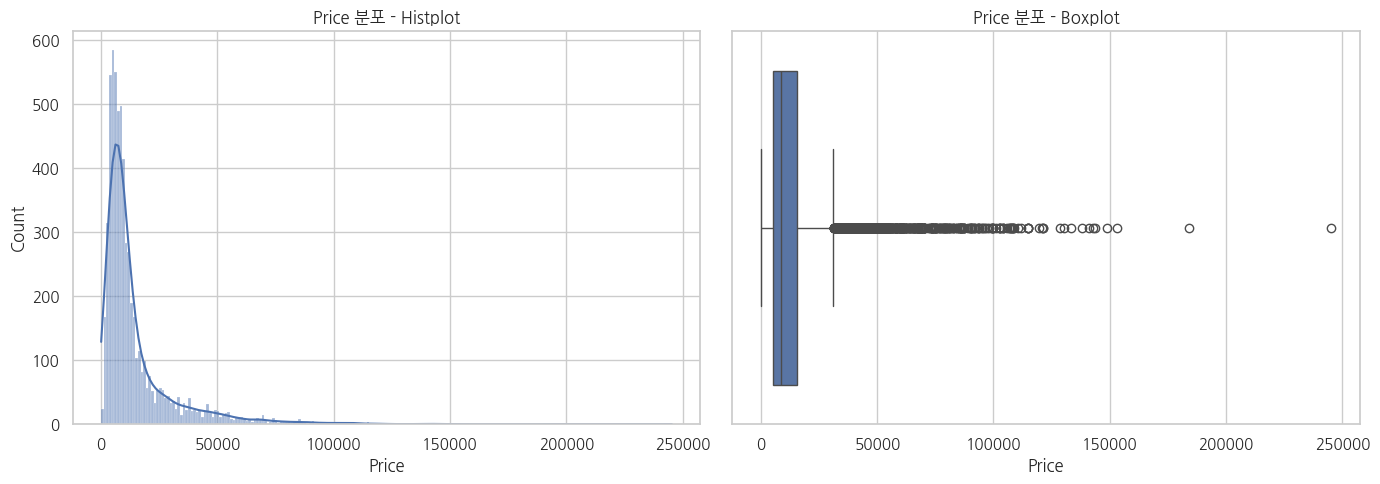

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df_model_base["Price"], kde=True, ax=axes[0])
axes[0].set_title("Price 분포 - Histplot")

sns.boxplot(x=df_model_base["Price"], ax=axes[1])
axes[1].set_title("Price 분포 - Boxplot")

plt.tight_layout()
plt.show()

In [11]:
# ============================================================
# New_Price 삭제
# ============================================================

def drop_high_missing_columns(df):
    df = df.copy()
    shape_before = df.shape

    if "New_Price" in df.columns:
        df = df.drop(columns=["New_Price"])
        print("New_Price 컬럼 삭제 완료")
    else:
        print("New_Price 컬럼이 없어 삭제하지 않음")

    print("New_Price 삭제 전 shape:", shape_before)
    print("New_Price 삭제 후 shape:", df.shape)

    return df


df_model_base = drop_high_missing_columns(df_model_base)


New_Price 컬럼 삭제 완료
New_Price 삭제 전 shape: (6130, 14)
New_Price 삭제 후 shape: (6130, 13)


In [12]:
# ============================================================
# [팀원 수정 및 피드백 반영]: 최종 데이터 정제 및 Luxury 차량 분리
# ============================================================
# 지금까지 합의한 최종 흐름
# 1. Price 원본값은 유지한다. 로그 변환은 모델 학습 시점에만 적용한다.
# 2. IQR 이상치는 탐색만 하고 일괄 삭제하지 않는다.
# 3. Engine과 Power가 모두 높은 차량을 Luxury로 정의한다.
# 4. Luxury == 1 차량은 별도 데이터셋(df_luxury_cars)으로 보관한다.
# 5. 이후 EDA / 통계검정 / 모델링에는 Luxury 차량을 제외한 일반 차량 데이터만 사용한다.
# ============================================================

print("[최종 파생변수 생성 및 Luxury 차량 분리 시작]")
print("입력 데이터 df_model_base shape:", df_model_base.shape)

# ------------------------------------------------------------
# 1. Vehicle_Age 생성
# ------------------------------------------------------------
shape_before = df_model_base.shape

df_model_with_luxury = df_model_base.copy().reset_index(drop=True)
df_model_with_luxury["Vehicle_Age"] = CURRENT_YEAR - df_model_with_luxury["Year"]

print()
print("[1] Vehicle_Age 생성")
print("생성 전 shape:", shape_before)
print("생성 후 shape:", df_model_with_luxury.shape)

# ------------------------------------------------------------
# 2. Engine / Power 75% 분위수 기준 Luxury 생성
# ------------------------------------------------------------
# Luxury 기준:
# Engine이 75% 분위수 이상이거나, Power도 75% 분위수 이상인 차량만 Luxury = 1
engine_q75 = df_model_with_luxury["Engine"].quantile(0.75) + 1.5*(df_model_with_luxury["Engine"].quantile(0.75) - df_model_with_luxury["Engine"].quantile(0.25)) #이상치값인데 변수 다 바꾸 힘들어서 q75으로 둠
power_q75 = df_model_with_luxury["Power"].quantile(0.75) + 1.5*(df_model_with_luxury["Power"].quantile(0.75) - df_model_with_luxury["Power"].quantile(0.25))

df_model_with_luxury["Luxury"] = np.where(
    (df_model_with_luxury["Engine"] >= engine_q75) |
    (df_model_with_luxury["Power"] >= power_q75),
    1,
    0
)

print()
print("[2] Luxury 생성 기준")
print(f"Engine 75% 분위수: {engine_q75:.2f}")
print(f"Power 75% 분위수: {power_q75:.2f}")
print("Luxury 값별 데이터 수:")
display(df_model_with_luxury["Luxury"].value_counts().sort_index())

# ------------------------------------------------------------
# 3. Luxury 차량 분리 및 분석 데이터에서 제외
# ------------------------------------------------------------
shape_before = df_model_with_luxury.shape

df_luxury_cars = (
    df_model_with_luxury[df_model_with_luxury["Luxury"] == 1]
    .copy()
    .reset_index(drop=True)
)

df_model_no_outlier_removed = (
    df_model_with_luxury[df_model_with_luxury["Luxury"] == 0]
    .copy()
    .reset_index(drop=True)
)

print()
print("[3] Luxury 차량 분리 및 분석 데이터에서 제외")
print("분리 전 df_model_with_luxury shape:", shape_before)
print("Luxury 차량 df_luxury_cars shape:", df_luxury_cars.shape)
print("Luxury 제외 후 분석/모델링용 df_model_no_outlier_removed shape:", df_model_no_outlier_removed.shape)
print("분석/모델링 데이터에서 제외된 Luxury 차량 수:", len(df_luxury_cars))

print()
print("분석/모델링용 데이터의 Luxury 값 확인")
display(df_model_no_outlier_removed["Luxury"].value_counts().sort_index())

display(
    df_model_with_luxury[
        ["Name", "Year", "Vehicle_Age", "Engine", "Power", "Luxury", "Price"]
    ].head()
)


[최종 파생변수 생성 및 Luxury 차량 분리 시작]
입력 데이터 df_model_base shape: (6130, 13)

[1] Vehicle_Age 생성
생성 전 shape: (6130, 13)
생성 후 shape: (6130, 14)

[2] Luxury 생성 기준
Engine 75% 분위수: 3123.00
Power 75% 분위수: 232.75
Luxury 값별 데이터 수:


,count
Luxury,
0,5871
1,259



[3] Luxury 차량 분리 및 분석 데이터에서 제외
분리 전 df_model_with_luxury shape: (6130, 15)
Luxury 차량 df_luxury_cars shape: (259, 15)
Luxury 제외 후 분석/모델링용 df_model_no_outlier_removed shape: (5871, 15)
분석/모델링 데이터에서 제외된 Luxury 차량 수: 259

분석/모델링용 데이터의 Luxury 값 확인


,count
Luxury,
0,5871


,Name,Year,Vehicle_Age,Engine,Power,Luxury,Price
0,Maruti Wagon R LXI CNG,2010,16,998.0,58.16,0,2682.68
1,Hyundai Creta 1.6 CRDi SX Option,2015,11,1582.0,126.20,0,19162.00
2,Honda Jazz V,2011,15,1199.0,88.70,0,6898.32
3,Maruti Ertiga VDI,2012,14,1248.0,88.76,0,9197.76
4,Audi A4 New 2.0 TDI Multitronic,2013,13,1968.0,140.80,0,27194.71


## 4. 이상치 확인 및 IQR 기준 계산

`Kilometers_Driven`의 비정상 입력값은 앞 단계에서 `6,000,000 이상`이라는 도메인 기준으로 제거했습니다. 여기서는 주요 연속형 변수의 Boxplot과 IQR 기준을 확인합니다.

중고차 데이터에서는 고가 차량, 고출력 차량, 고배기량 차량이 실제로 존재할 수 있으므로, IQR 기준 제거 데이터는 모델 성능 비교용 버전으로만 사용합니다.

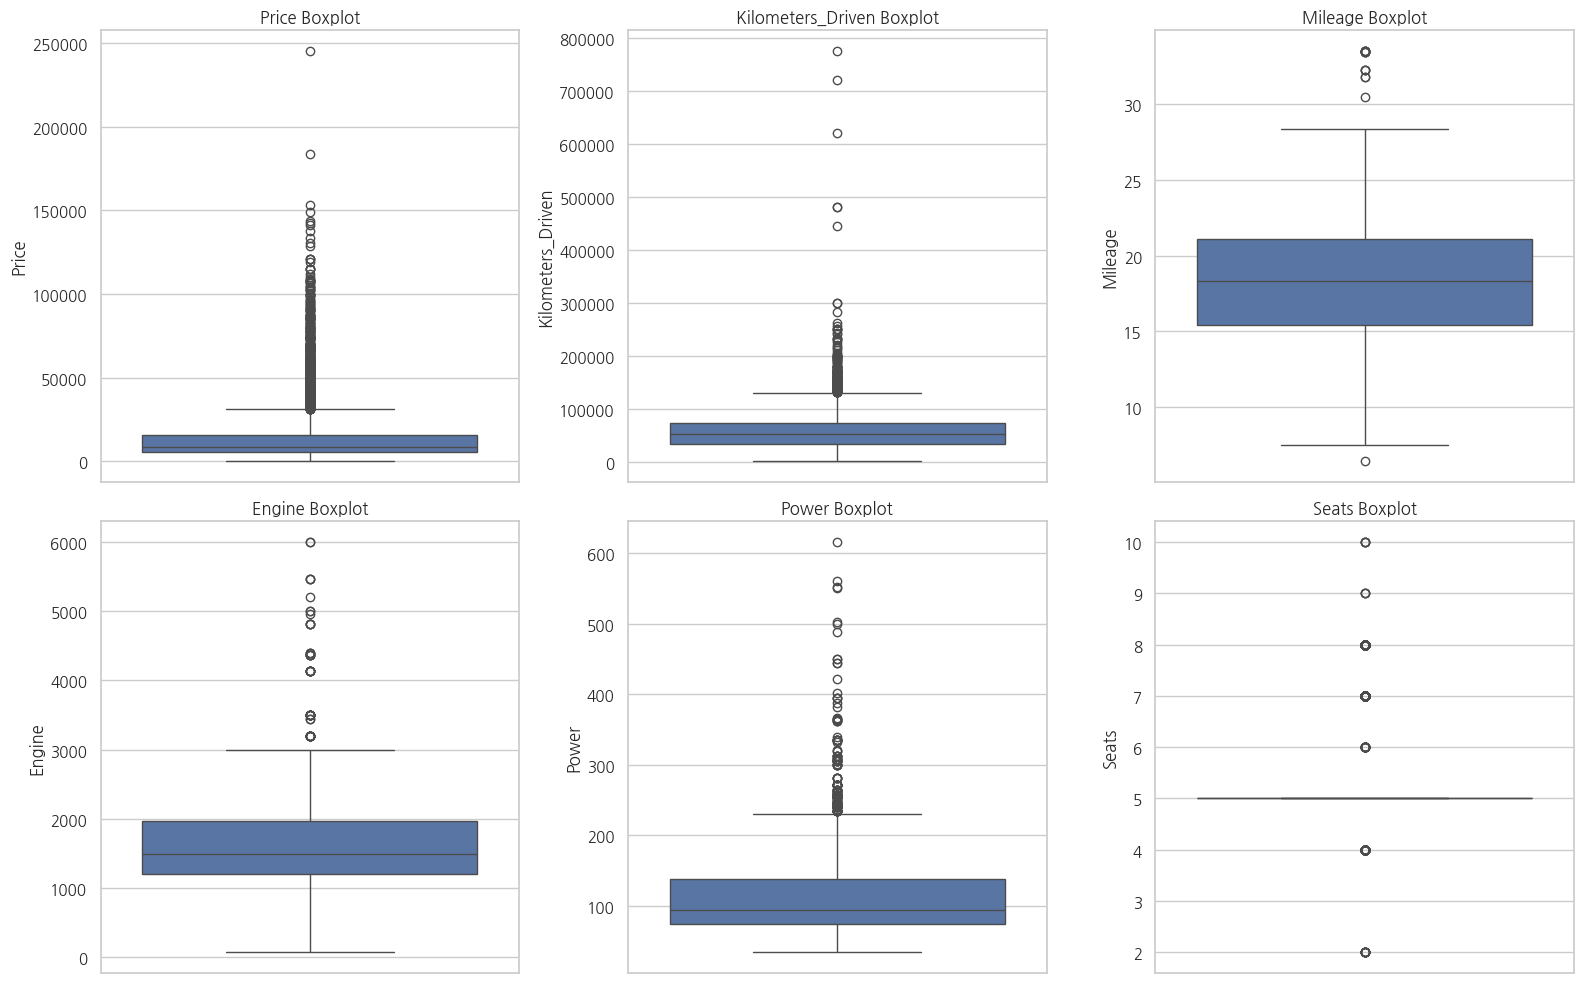

In [13]:
continuous_cols = [
    "Price",
    "Kilometers_Driven",
    "Mileage",
    "Engine",
    "Power",
    "Seats"
]

continuous_cols = [col for col in continuous_cols if col in df_model_base.columns]

plt.figure(figsize=(16, 10))

for i, col in enumerate(continuous_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df_model_base[col])
    plt.title(f"{col} Boxplot")

plt.tight_layout()
plt.show()

Luxury 제거 후 분석 데이터 shape: (5871, 15)


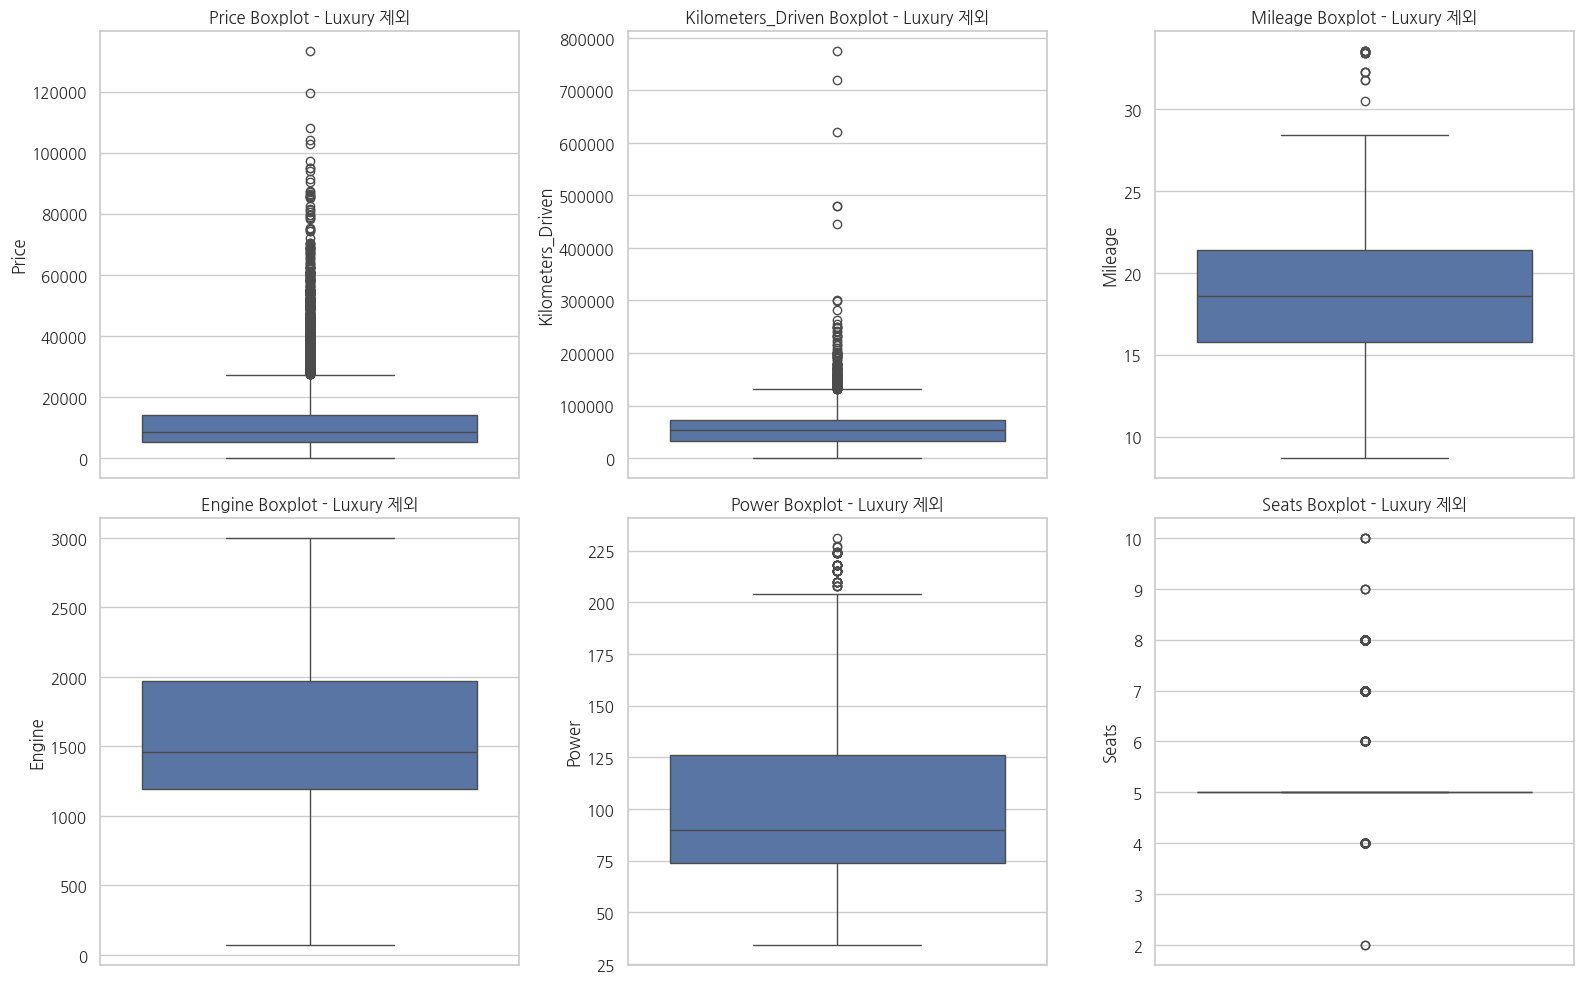

In [14]:
# ============================================================
# Luxury 차량 제거 후 주요 연속형 변수 Boxplot 재확인
# ============================================================
# 위 IQR 탐색은 Luxury 차량이 포함된 전체 데이터 기준이었다.
# 아래 그래프는 Luxury == 1 차량을 제거한 일반 차량 데이터 기준으로
# Price, Kilometers_Driven, Mileage, Engine, Power, Seats의 분포를 다시 확인한다.

print("Luxury 제거 후 분석 데이터 shape:", df_model_no_outlier_removed.shape)

continuous_cols_after_luxury = [
    "Price",
    "Kilometers_Driven",
    "Mileage",
    "Engine",
    "Power",
    "Seats"
]

continuous_cols_after_luxury = [
    col for col in continuous_cols_after_luxury
    if col in df_model_no_outlier_removed.columns
]

plt.figure(figsize=(16, 10))

for i, col in enumerate(continuous_cols_after_luxury, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df_model_no_outlier_removed[col])
    plt.title(f"{col} Boxplot - Luxury 제외")

plt.tight_layout()
plt.show()

In [17]:
# ============================================================
# Luxury 차량 제거 후 IQR 기준 이상치 개수 재확인
# ============================================================
# 이 셀도 탐색용이다. 여기서도 IQR 기준 행 삭제는 하지 않는다.

iqr_report_after_luxury = iqr_outlier_report(
    df_model_no_outlier_removed,
    continuous_cols_after_luxury
)

display(iqr_report_after_luxury)

NameError: name 'iqr_outlier_report' is not defined

In [18]:
#Luxury 제거 전
def iqr_outlier_report(df, cols):
    report = []

    for col in cols:
        data = df[col].dropna()

        q1 = data.quantile(0.25)
        q3 = data.quantile(0.75)
        iqr = q3 - q1

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        outlier_mask = (df[col] < lower) | (df[col] > upper)
        outlier_count = outlier_mask.sum()
        outlier_ratio = outlier_count / len(df) * 100

        report.append({
            "variable": col,
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
            "lower_bound": lower,
            "upper_bound": upper,
            "outlier_count": outlier_count,
            "outlier_ratio(%)": outlier_ratio
        })

    return pd.DataFrame(report)


iqr_report = iqr_outlier_report(df_model_base, continuous_cols)
display(iqr_report)

,variable,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_ratio(%)
0,Price,5399.8525,15747.3325,10347.48,-10121.3675,31268.5525,709,11.566069
1,Kilometers_Driven,33000.0000,72019.0000,39019.00,-25528.5000,130547.5000,203,3.311582
2,Mileage,15.4000,21.1000,5.70,6.8500,29.6500,16,0.261011
3,Engine,1198.0000,1968.0000,770.00,43.0000,3123.0000,59,0.962480
4,Power,75.0000,138.1000,63.10,-19.6500,232.7500,241,3.931485
5,Seats,5.0000,5.0000,0.00,5.0000,5.0000,988,16.117455


In [19]:
# IQR 이상치 후보 중 실제 차량 특성상 가능한 값인지 직접 확인합니다.
candidate_cols = ["Name", "Brand", "Year", "Kilometers_Driven", "Mileage", "Engine", "Power", "Seats", "Price"]
candidate_cols = [col for col in candidate_cols if col in df_model_base.columns]

for col in continuous_cols :
    print(f"\n===== {col} 상위값 확인 =====")
    display(df_model_base.sort_values(col, ascending=False)[candidate_cols].head(10))


===== Price 상위값 확인 =====


,Name,Brand,Year,Kilometers_Driven,Mileage,Engine,Power,Seats,Price
4029,Land Rover Range Rover 3.0 Diesel LWB Vogue,Land,2017,25000,13.33,2993.0,255.00,5.0,245273.60
5715,Lamborghini Gallardo Coupe,Lamborghini,2011,6500,6.40,5204.0,560.00,2.0,183955.20
5852,Jaguar F Type 5.0 V8 S,Jaguar,2015,8000,12.50,5000.0,488.10,2.0,153296.00
1479,Land Rover Range Rover Sport SE,Land,2019,26013,12.65,2993.0,255.00,5.0,148804.43
1946,BMW 7 Series 740Li,BMW,2018,28060,12.05,2979.0,320.00,5.0,143592.36
1956,BMW 7 Series 740Li,BMW,2017,17465,12.05,2979.0,320.00,5.0,142565.28
6090,Mercedes-Benz GLE 350d,Mercedes-Benz,2016,50000,11.57,2987.0,254.79,5.0,141047.65
4635,Mercedes-Benz SLK-Class 55 AMG,Mercedes-Benz,2014,3000,12.00,5461.0,421.00,2.0,137966.40
6044,Mercedes-Benz E-Class E 220 d,Mercedes-Benz,2017,15000,12.60,1950.0,191.34,5.0,133321.53
5470,BMW X6 xDrive 40d M Sport,BMW,2015,97003,15.87,2993.0,308.43,5.0,130301.60



===== Kilometers_Driven 상위값 확인 =====


,Name,Brand,Year,Kilometers_Driven,Mileage,Engine,Power,Seats,Price
333,Skoda Octavia Ambition Plus 2.0 TDI AT,Skoda,2013,775000,19.30,1968.0,141.00,5.0,11497.20
1832,Volkswagen Vento Diesel Highline,Volkswagen,2013,720000,20.54,1598.0,103.60,5.0,9044.46
351,Hyundai i10 Magna 1.2,Hyundai,2009,620000,20.36,1197.0,78.90,5.0,4138.99
3050,Honda City i VTEC SV,Honda,2015,480000,17.40,1497.0,117.30,5.0,7664.80
2785,Volkswagen Jetta 2013-2015 2.0L TDI Highline AT,Volkswagen,2015,480000,16.96,1968.0,138.03,5.0,19928.48
4437,Hyundai i20 Magna Optional 1.2,Hyundai,2013,445000,18.50,1197.0,82.90,5.0,6821.67
3600,Tata Indigo LS,Tata,2008,300000,17.00,1405.0,70.00,5.0,1532.96
1502,Toyota Innova 2.5 G (Diesel) 8 Seater BS IV,Toyota,2005,299322,12.80,2494.0,102.00,8.0,6131.84
1947,Skoda Superb 1.8 TSI MT,Skoda,2012,282000,13.14,1798.0,160.00,5.0,5058.77
28,Toyota Innova 2.5 V Diesel 7-seater,Toyota,2007,262000,12.80,2494.0,102.00,7.0,6131.84



===== Mileage 상위값 확인 =====


,Name,Brand,Year,Kilometers_Driven,Mileage,Engine,Power,Seats,Price
4091,Maruti Wagon R CNG LXI,Maruti,2014,47200,33.54,998.0,67.04,5.0,4368.94
2030,Maruti Wagon R CNG LXI,Maruti,2013,54000,33.54,998.0,67.04,5.0,4675.53
3086,Maruti Wagon R CNG LXI,Maruti,2014,74663,33.54,998.0,67.04,5.0,4982.12
2337,Maruti Wagon R CNG LXI,Maruti,2014,29202,33.54,998.0,67.04,5.0,5978.54
1311,Maruti Wagon R CNG LXI,Maruti,2013,79494,33.54,998.0,67.04,5.0,4537.56
3505,Maruti Alto 800 2016-2019 CNG LXI,Maruti,2015,18000,33.44,796.0,40.30,4.0,4598.88
3820,Maruti Alto 800 2016-2019 CNG LXI,Maruti,2012,65537,33.44,796.0,40.30,4.0,3219.22
1250,Maruti Alto 800 2016-2019 CNG LXI,Maruti,2018,10600,33.44,796.0,40.30,4.0,5365.36
4712,Maruti Alto 800 2016-2019 CNG LXI,Maruti,2017,24310,33.44,796.0,40.30,4.0,5671.95
6059,Maruti Alto K10 LXI CNG Optional,Maruti,2017,33000,32.26,998.0,58.20,4.0,7143.59


... (2 outputs left out)


===== Power 상위값 확인 =====


,Name,Brand,Year,Kilometers_Driven,Mileage,Engine,Power,Seats,Price
5994,Bentley Flying Spur W12,Bentley,2008,31200,10.20,5998.0,616.0,5.0,5748.60
5715,Lamborghini Gallardo Coupe,Lamborghini,2011,6500,6.40,5204.0,560.0,2.0,183955.20
5457,Bentley Continental Flying Spur,Bentley,2006,48000,8.60,5998.0,552.0,4.0,90444.64
2070,Porsche Cayenne Turbo S,Porsche,2010,35000,11.90,4806.0,550.0,5.0,49054.72
5029,Jaguar XJ 5.0 L V8 Supercharged,Jaguar,2011,43686,10.50,5000.0,503.0,4.0,77659.75
68,Porsche Cayenne 2009-2014 Turbo,Porsche,2008,73000,8.50,4806.0,500.0,5.0,22227.92
5852,Jaguar F Type 5.0 V8 S,Jaguar,2015,8000,12.50,5000.0,488.1,2.0,153296.00
4573,BMW 6 Series 650i Coupe,BMW,2010,65329,7.94,4395.0,450.0,4.0,31762.93
4764,BMW 6 Series 630i Coupe,BMW,2011,5900,7.94,4395.0,450.0,4.0,72815.60
4011,Audi RS5 Coupe,Audi,2013,23312,11.05,2894.0,444.0,4.0,62084.88



===== Seats 상위값 확인 =====


,Name,Brand,Year,Kilometers_Driven,Mileage,Engine,Power,Seats,Price
902,Tata Sumo DX,Tata,2013,20000,14.07,1978.0,83.1,10.0,8048.04
800,Toyota Qualis FS B2,Toyota,2004,77757,13.10,2446.0,75.0,10.0,5365.36
2540,Chevrolet Tavera LS B3 10 Seats BSIII,Chevrolet,2015,120000,14.80,2499.0,80.0,10.0,8431.28
1879,Toyota Qualis FS B3,Toyota,2002,63000,13.10,2446.0,75.0,10.0,5595.30
1325,Mahindra Scorpio LX BS IV,Mahindra,2007,74112,12.05,2179.0,120.0,9.0,6285.14
2325,Mahindra Xylo D2 Maxx,Mahindra,2016,150000,14.95,2489.0,93.7,9.0,6898.32
2280,Chevrolet Tavera LT 9 Str BS IV,Chevrolet,2012,67132,13.58,2499.0,78.0,9.0,7281.56
59,Toyota Innova Crysta 2.4 GX MT 8S,Toyota,2017,22000,13.68,2393.0,147.8,8.0,25293.84
1204,Mahindra Scorpio VLX 2.2 mHawk BSIII,Mahindra,2012,62729,12.05,2179.0,120.0,8.0,9688.31
6053,Toyota Innova Crysta 2.8 GX AT 8S,Toyota,2018,23000,11.36,2755.0,171.5,8.0,32192.16


In [20]:
# ============================================================
# IQR 이상치 처리는 탐색용으로만 유지
# ============================================================
# 주의:
# - IQR 기준 이상치 개수와 비율은 위 iqr_report에서 확인한다.
# - IQR 기준에 해당하는 행을 일괄 삭제하지 않는다.
# - 실제 삭제는 중복행, Kilometers_Driven >= 6,000,000, Mileage == 0, Seats == 0에만 적용했다.
# - Engine / Power가 모두 높은 차량은 Luxury로 분리했고, 분석/모델링용 데이터에서는 제외했다.

print("IQR 이상치 처리는 탐색용으로만 유지합니다.")
print("IQR 기준 행 삭제는 수행하지 않았습니다.")
print("Luxury 분리 전 데이터 df_model_with_luxury shape:", df_model_with_luxury.shape)
print("Luxury 제외 후 분석/모델링 데이터 df_model_no_outlier_removed shape:", df_model_no_outlier_removed.shape)


IQR 이상치 처리는 탐색용으로만 유지합니다.
IQR 기준 행 삭제는 수행하지 않았습니다.
Luxury 분리 전 데이터 df_model_with_luxury shape: (6130, 15)
Luxury 제외 후 분석/모델링 데이터 df_model_no_outlier_removed shape: (5871, 15)


In [21]:
# ============================================================
# IQR 이상치 후보 상세 확인
# ============================================================
# IQR 기준 삭제는 하지 않고, 실제 차량 특성상 가능한 값인지 상위값만 확인한다.

candidate_cols = ["Name", "Brand", "Year", "Kilometers_Driven", "Mileage", "Engine", "Power", "Seats", "Price", "Luxury"]
candidate_cols = [col for col in candidate_cols if col in df_model_with_luxury.columns]

for col in continuous_cols:
    print()
    print(f"===== {col} 상위값 확인 =====")
    display(df_model_with_luxury.sort_values(col, ascending=False)[candidate_cols].head(10))



===== Price 상위값 확인 =====


,Name,Brand,Year,Kilometers_Driven,Mileage,Engine,Power,Seats,Price,Luxury
4029,Land Rover Range Rover 3.0 Diesel LWB Vogue,Land,2017,25000,13.33,2993.0,255.00,5.0,245273.60,1
5715,Lamborghini Gallardo Coupe,Lamborghini,2011,6500,6.40,5204.0,560.00,2.0,183955.20,1
5852,Jaguar F Type 5.0 V8 S,Jaguar,2015,8000,12.50,5000.0,488.10,2.0,153296.00,1
1479,Land Rover Range Rover Sport SE,Land,2019,26013,12.65,2993.0,255.00,5.0,148804.43,1
1946,BMW 7 Series 740Li,BMW,2018,28060,12.05,2979.0,320.00,5.0,143592.36,1
1956,BMW 7 Series 740Li,BMW,2017,17465,12.05,2979.0,320.00,5.0,142565.28,1
6090,Mercedes-Benz GLE 350d,Mercedes-Benz,2016,50000,11.57,2987.0,254.79,5.0,141047.65,1
4635,Mercedes-Benz SLK-Class 55 AMG,Mercedes-Benz,2014,3000,12.00,5461.0,421.00,2.0,137966.40,1
6044,Mercedes-Benz E-Class E 220 d,Mercedes-Benz,2017,15000,12.60,1950.0,191.34,5.0,133321.53,0
5470,BMW X6 xDrive 40d M Sport,BMW,2015,97003,15.87,2993.0,308.43,5.0,130301.60,1



===== Kilometers_Driven 상위값 확인 =====


,Name,Brand,Year,Kilometers_Driven,Mileage,Engine,Power,Seats,Price,Luxury
333,Skoda Octavia Ambition Plus 2.0 TDI AT,Skoda,2013,775000,19.30,1968.0,141.00,5.0,11497.20,0
1832,Volkswagen Vento Diesel Highline,Volkswagen,2013,720000,20.54,1598.0,103.60,5.0,9044.46,0
351,Hyundai i10 Magna 1.2,Hyundai,2009,620000,20.36,1197.0,78.90,5.0,4138.99,0
3050,Honda City i VTEC SV,Honda,2015,480000,17.40,1497.0,117.30,5.0,7664.80,0
2785,Volkswagen Jetta 2013-2015 2.0L TDI Highline AT,Volkswagen,2015,480000,16.96,1968.0,138.03,5.0,19928.48,0
4437,Hyundai i20 Magna Optional 1.2,Hyundai,2013,445000,18.50,1197.0,82.90,5.0,6821.67,0
3600,Tata Indigo LS,Tata,2008,300000,17.00,1405.0,70.00,5.0,1532.96,0
1502,Toyota Innova 2.5 G (Diesel) 8 Seater BS IV,Toyota,2005,299322,12.80,2494.0,102.00,8.0,6131.84,0
1947,Skoda Superb 1.8 TSI MT,Skoda,2012,282000,13.14,1798.0,160.00,5.0,5058.77,0
28,Toyota Innova 2.5 V Diesel 7-seater,Toyota,2007,262000,12.80,2494.0,102.00,7.0,6131.84,0



===== Mileage 상위값 확인 =====


,Name,Brand,Year,Kilometers_Driven,Mileage,Engine,Power,Seats,Price,Luxury
4091,Maruti Wagon R CNG LXI,Maruti,2014,47200,33.54,998.0,67.04,5.0,4368.94,0
2030,Maruti Wagon R CNG LXI,Maruti,2013,54000,33.54,998.0,67.04,5.0,4675.53,0
3086,Maruti Wagon R CNG LXI,Maruti,2014,74663,33.54,998.0,67.04,5.0,4982.12,0
2337,Maruti Wagon R CNG LXI,Maruti,2014,29202,33.54,998.0,67.04,5.0,5978.54,0
1311,Maruti Wagon R CNG LXI,Maruti,2013,79494,33.54,998.0,67.04,5.0,4537.56,0
3505,Maruti Alto 800 2016-2019 CNG LXI,Maruti,2015,18000,33.44,796.0,40.30,4.0,4598.88,0
3820,Maruti Alto 800 2016-2019 CNG LXI,Maruti,2012,65537,33.44,796.0,40.30,4.0,3219.22,0
1250,Maruti Alto 800 2016-2019 CNG LXI,Maruti,2018,10600,33.44,796.0,40.30,4.0,5365.36,0
4712,Maruti Alto 800 2016-2019 CNG LXI,Maruti,2017,24310,33.44,796.0,40.30,4.0,5671.95,0
6059,Maruti Alto K10 LXI CNG Optional,Maruti,2017,33000,32.26,998.0,58.20,4.0,7143.59,0


... (2 outputs left out)


===== Power 상위값 확인 =====


,Name,Brand,Year,Kilometers_Driven,Mileage,Engine,Power,Seats,Price,Luxury
5994,Bentley Flying Spur W12,Bentley,2008,31200,10.20,5998.0,616.0,5.0,5748.60,1
5715,Lamborghini Gallardo Coupe,Lamborghini,2011,6500,6.40,5204.0,560.0,2.0,183955.20,1
5457,Bentley Continental Flying Spur,Bentley,2006,48000,8.60,5998.0,552.0,4.0,90444.64,1
2070,Porsche Cayenne Turbo S,Porsche,2010,35000,11.90,4806.0,550.0,5.0,49054.72,1
5029,Jaguar XJ 5.0 L V8 Supercharged,Jaguar,2011,43686,10.50,5000.0,503.0,4.0,77659.75,1
68,Porsche Cayenne 2009-2014 Turbo,Porsche,2008,73000,8.50,4806.0,500.0,5.0,22227.92,1
5852,Jaguar F Type 5.0 V8 S,Jaguar,2015,8000,12.50,5000.0,488.1,2.0,153296.00,1
4573,BMW 6 Series 650i Coupe,BMW,2010,65329,7.94,4395.0,450.0,4.0,31762.93,1
4764,BMW 6 Series 630i Coupe,BMW,2011,5900,7.94,4395.0,450.0,4.0,72815.60,1
4011,Audi RS5 Coupe,Audi,2013,23312,11.05,2894.0,444.0,4.0,62084.88,1



===== Seats 상위값 확인 =====


,Name,Brand,Year,Kilometers_Driven,Mileage,Engine,Power,Seats,Price,Luxury
902,Tata Sumo DX,Tata,2013,20000,14.07,1978.0,83.1,10.0,8048.04,0
800,Toyota Qualis FS B2,Toyota,2004,77757,13.10,2446.0,75.0,10.0,5365.36,0
2540,Chevrolet Tavera LS B3 10 Seats BSIII,Chevrolet,2015,120000,14.80,2499.0,80.0,10.0,8431.28,0
1879,Toyota Qualis FS B3,Toyota,2002,63000,13.10,2446.0,75.0,10.0,5595.30,0
1325,Mahindra Scorpio LX BS IV,Mahindra,2007,74112,12.05,2179.0,120.0,9.0,6285.14,0
2325,Mahindra Xylo D2 Maxx,Mahindra,2016,150000,14.95,2489.0,93.7,9.0,6898.32,0
2280,Chevrolet Tavera LT 9 Str BS IV,Chevrolet,2012,67132,13.58,2499.0,78.0,9.0,7281.56,0
59,Toyota Innova Crysta 2.4 GX MT 8S,Toyota,2017,22000,13.68,2393.0,147.8,8.0,25293.84,0
1204,Mahindra Scorpio VLX 2.2 mHawk BSIII,Mahindra,2012,62729,12.05,2179.0,120.0,8.0,9688.31,0
6053,Toyota Innova Crysta 2.8 GX AT 8S,Toyota,2018,23000,11.36,2755.0,171.5,8.0,32192.16,0


## 5. 파생변수 생성

`Vehicle_Age = 2026 - Year`로 차량 연식을 생성합니다.

추가로 `Engine`과 `Power`의 75% 분위수를 기준으로 고급/고성능 차량 여부를 나타내는 `Luxury` 변수를 생성합니다. `Engine`이 75% 분위수 이상이거나 `Power`가 75% 분위수 이상이면 `Luxury = 1`, 그렇지 않으면 `0`입니다.

In [22]:
# ============================================================
# 파생변수 생성 확인
# ============================================================
# Vehicle_Age와 Luxury는 앞 셀에서 생성 완료했다.
# 현재부터 분석/모델링은 Luxury 차량을 제외한 df_model_no_outlier_removed를 사용한다.

print("Luxury 분리 전 전체 데이터:", df_model_with_luxury.shape)
print("Luxury 차량 데이터:", df_luxury_cars.shape)
print("분석/모델링용 일반 차량 데이터:", df_model_no_outlier_removed.shape)

display(df_model_no_outlier_removed[["Year", "Vehicle_Age", "Engine", "Power", "Luxury", "Price"]].head())


Luxury 분리 전 전체 데이터: (6130, 15)
Luxury 차량 데이터: (259, 15)
분석/모델링용 일반 차량 데이터: (5871, 15)


,Year,Vehicle_Age,Engine,Power,Luxury,Price
0,2010,16,998.0,58.16,0,2682.68
1,2015,11,1582.0,126.20,0,19162.00
2,2011,15,1199.0,88.70,0,6898.32
3,2012,14,1248.0,88.76,0,9197.76
4,2013,13,1968.0,140.80,0,27194.71


## 6. 범주형 변수와 Price 관계 시각화

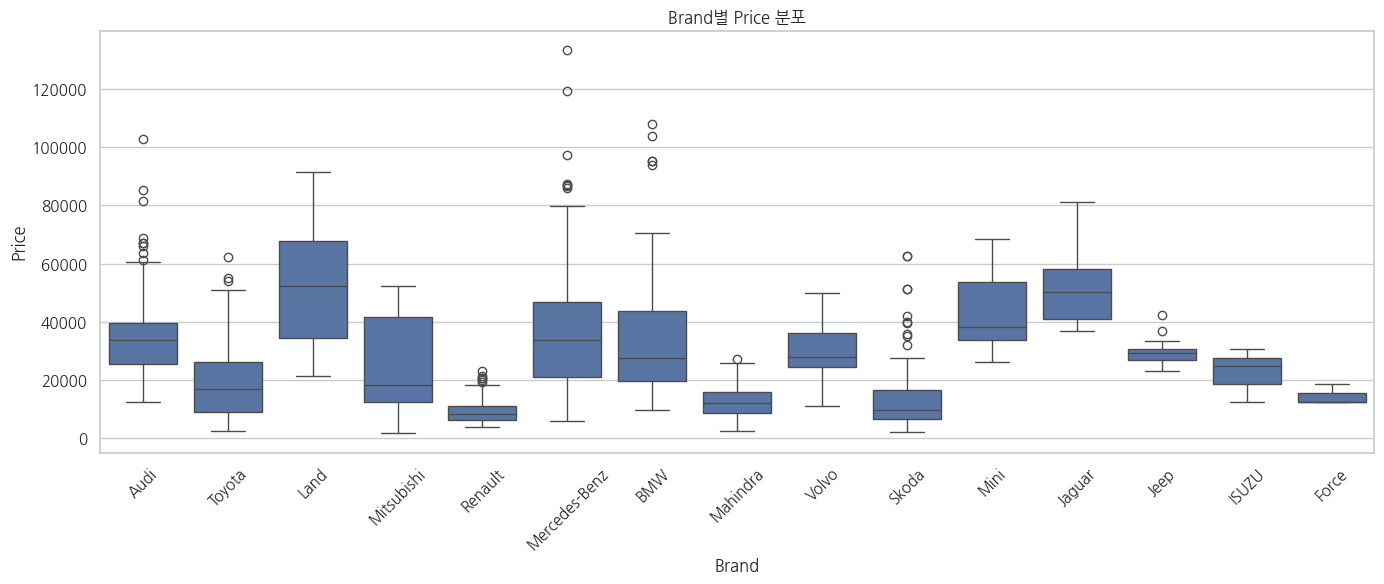

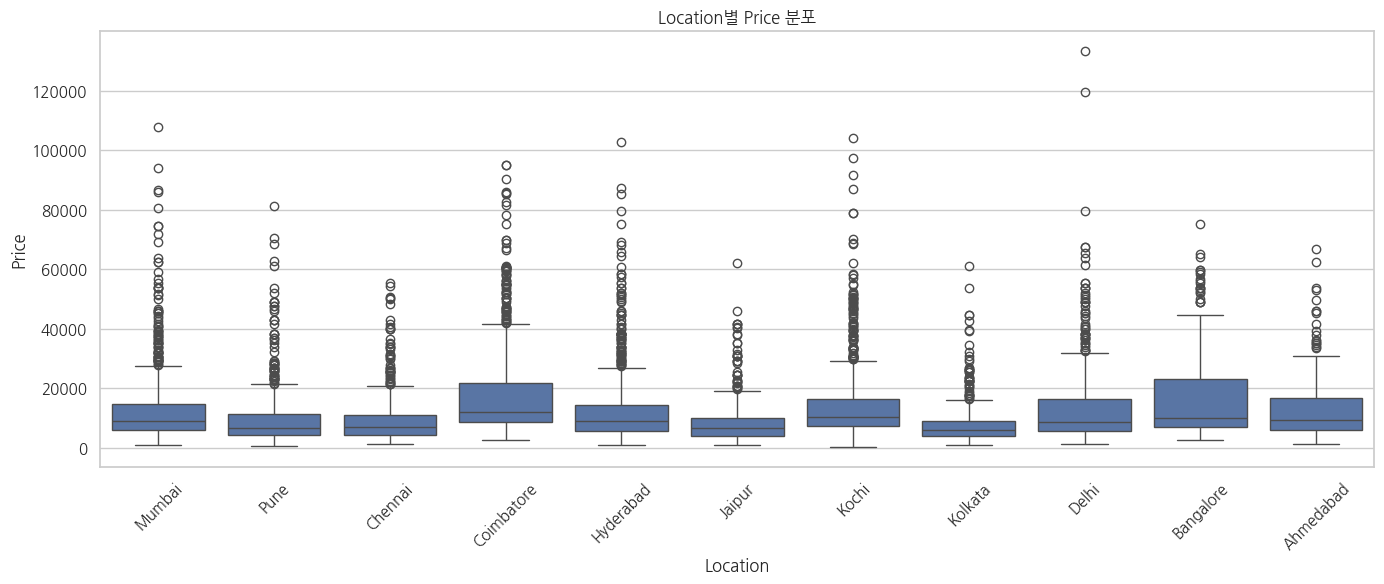

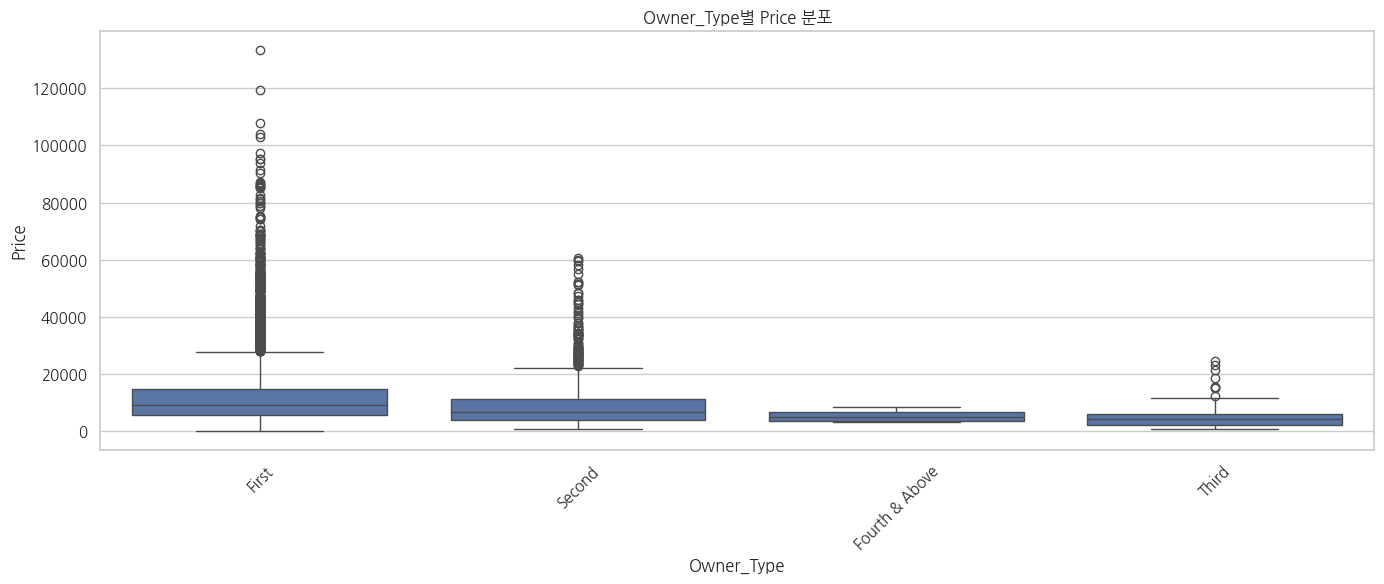

In [23]:

def boxplot_categorical_vs_price(df, cat_col, target="Price", top_n=15):
    temp = df[[cat_col, target]].dropna().copy()

    if temp[cat_col].nunique() > top_n:
        top_categories = (
            temp.groupby(cat_col)[target]
            .mean()
            .sort_values(ascending=False)
            .head(top_n)
            .index
        )
        temp = temp[temp[cat_col].isin(top_categories)]

    plt.figure(figsize=(14, 6))
    sns.boxplot(data=temp, x=cat_col, y=target)
    plt.title(f"{cat_col}별 {target} 분포")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


for cat_col in ["Brand", "Location", "Owner_Type"]:
    if cat_col in df_model_no_outlier_removed.columns:
        boxplot_categorical_vs_price(df_model_no_outlier_removed, cat_col)

Luxury 값별 데이터 수 - 분리 전 데이터 기준


,count
Luxury,
0,5871
1,259


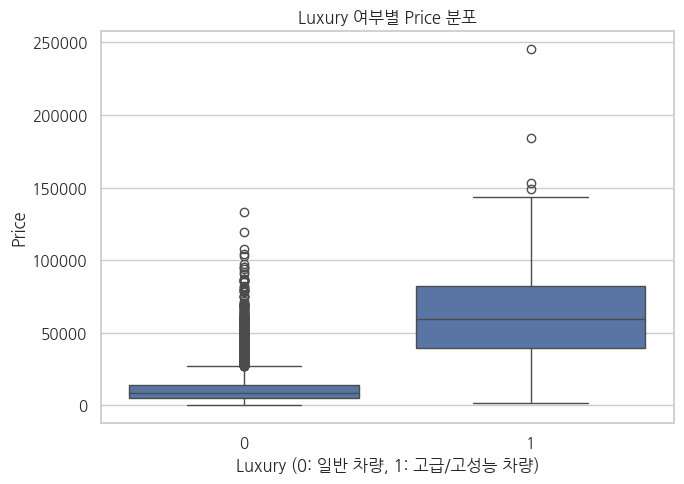

Location별 Luxury 차량 대수


,Location,Luxury_Count
0,Coimbatore,64
1,Mumbai,36
2,Bangalore,29
3,Hyderabad,29
4,Kochi,25
5,Chennai,22
6,Delhi,20
7,Kolkata,14
8,Pune,13
9,Ahmedabad,4


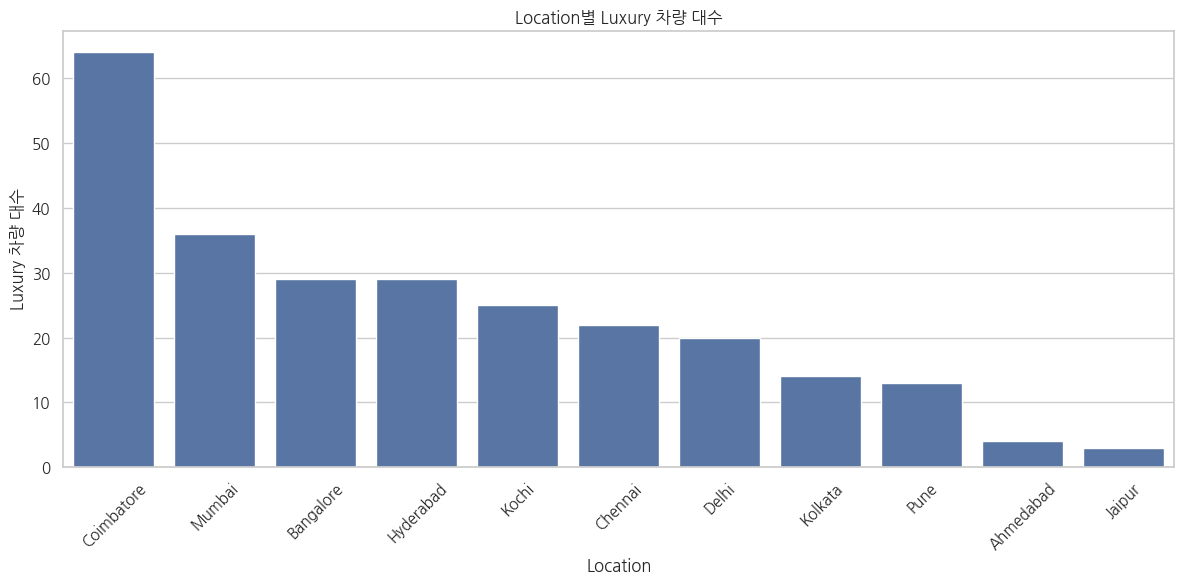

분석/모델링에 사용할 일반 차량 데이터 shape: (5871, 15)


In [24]:
# ============================================================
# Luxury 차량 Price 분포 및 Location별 수요 분석
# [팀원 수정 및 피드백 반영]
# ============================================================
# 이 셀은 Luxury 차량을 제외하기 전 데이터(df_model_with_luxury)를 사용해
# Luxury 그룹이 어떤 가격/지역 특성을 갖는지 확인한다.
# 이후 일반 차량 분석과 모델링은 df_model_no_outlier_removed를 사용한다.

print("Luxury 값별 데이터 수 - 분리 전 데이터 기준")
display(df_model_with_luxury["Luxury"].value_counts().sort_index())

plt.figure(figsize=(7, 5))
sns.boxplot(data=df_model_with_luxury, x="Luxury", y="Price")
plt.title("Luxury 여부별 Price 분포")
plt.xlabel("Luxury (0: 일반 차량, 1: 고급/고성능 차량)")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

luxury_location_counts = (
    df_luxury_cars
    .groupby("Location")
    .size()
    .sort_values(ascending=False)
)

print("Location별 Luxury 차량 대수")
display(luxury_location_counts.reset_index(name="Luxury_Count"))

plt.figure(figsize=(12, 6))
sns.barplot(
    x=luxury_location_counts.index,
    y=luxury_location_counts.values,
    order=luxury_location_counts.index
)
plt.title("Location별 Luxury 차량 대수")
plt.xlabel("Location")
plt.ylabel("Luxury 차량 대수")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("분석/모델링에 사용할 일반 차량 데이터 shape:", df_model_no_outlier_removed.shape)


## 7. 연속형 변수 시각화

Scatter Matrix와 개별 Scatter Plot으로 수치형 변수와 `Price`의 관계를 확인합니다.

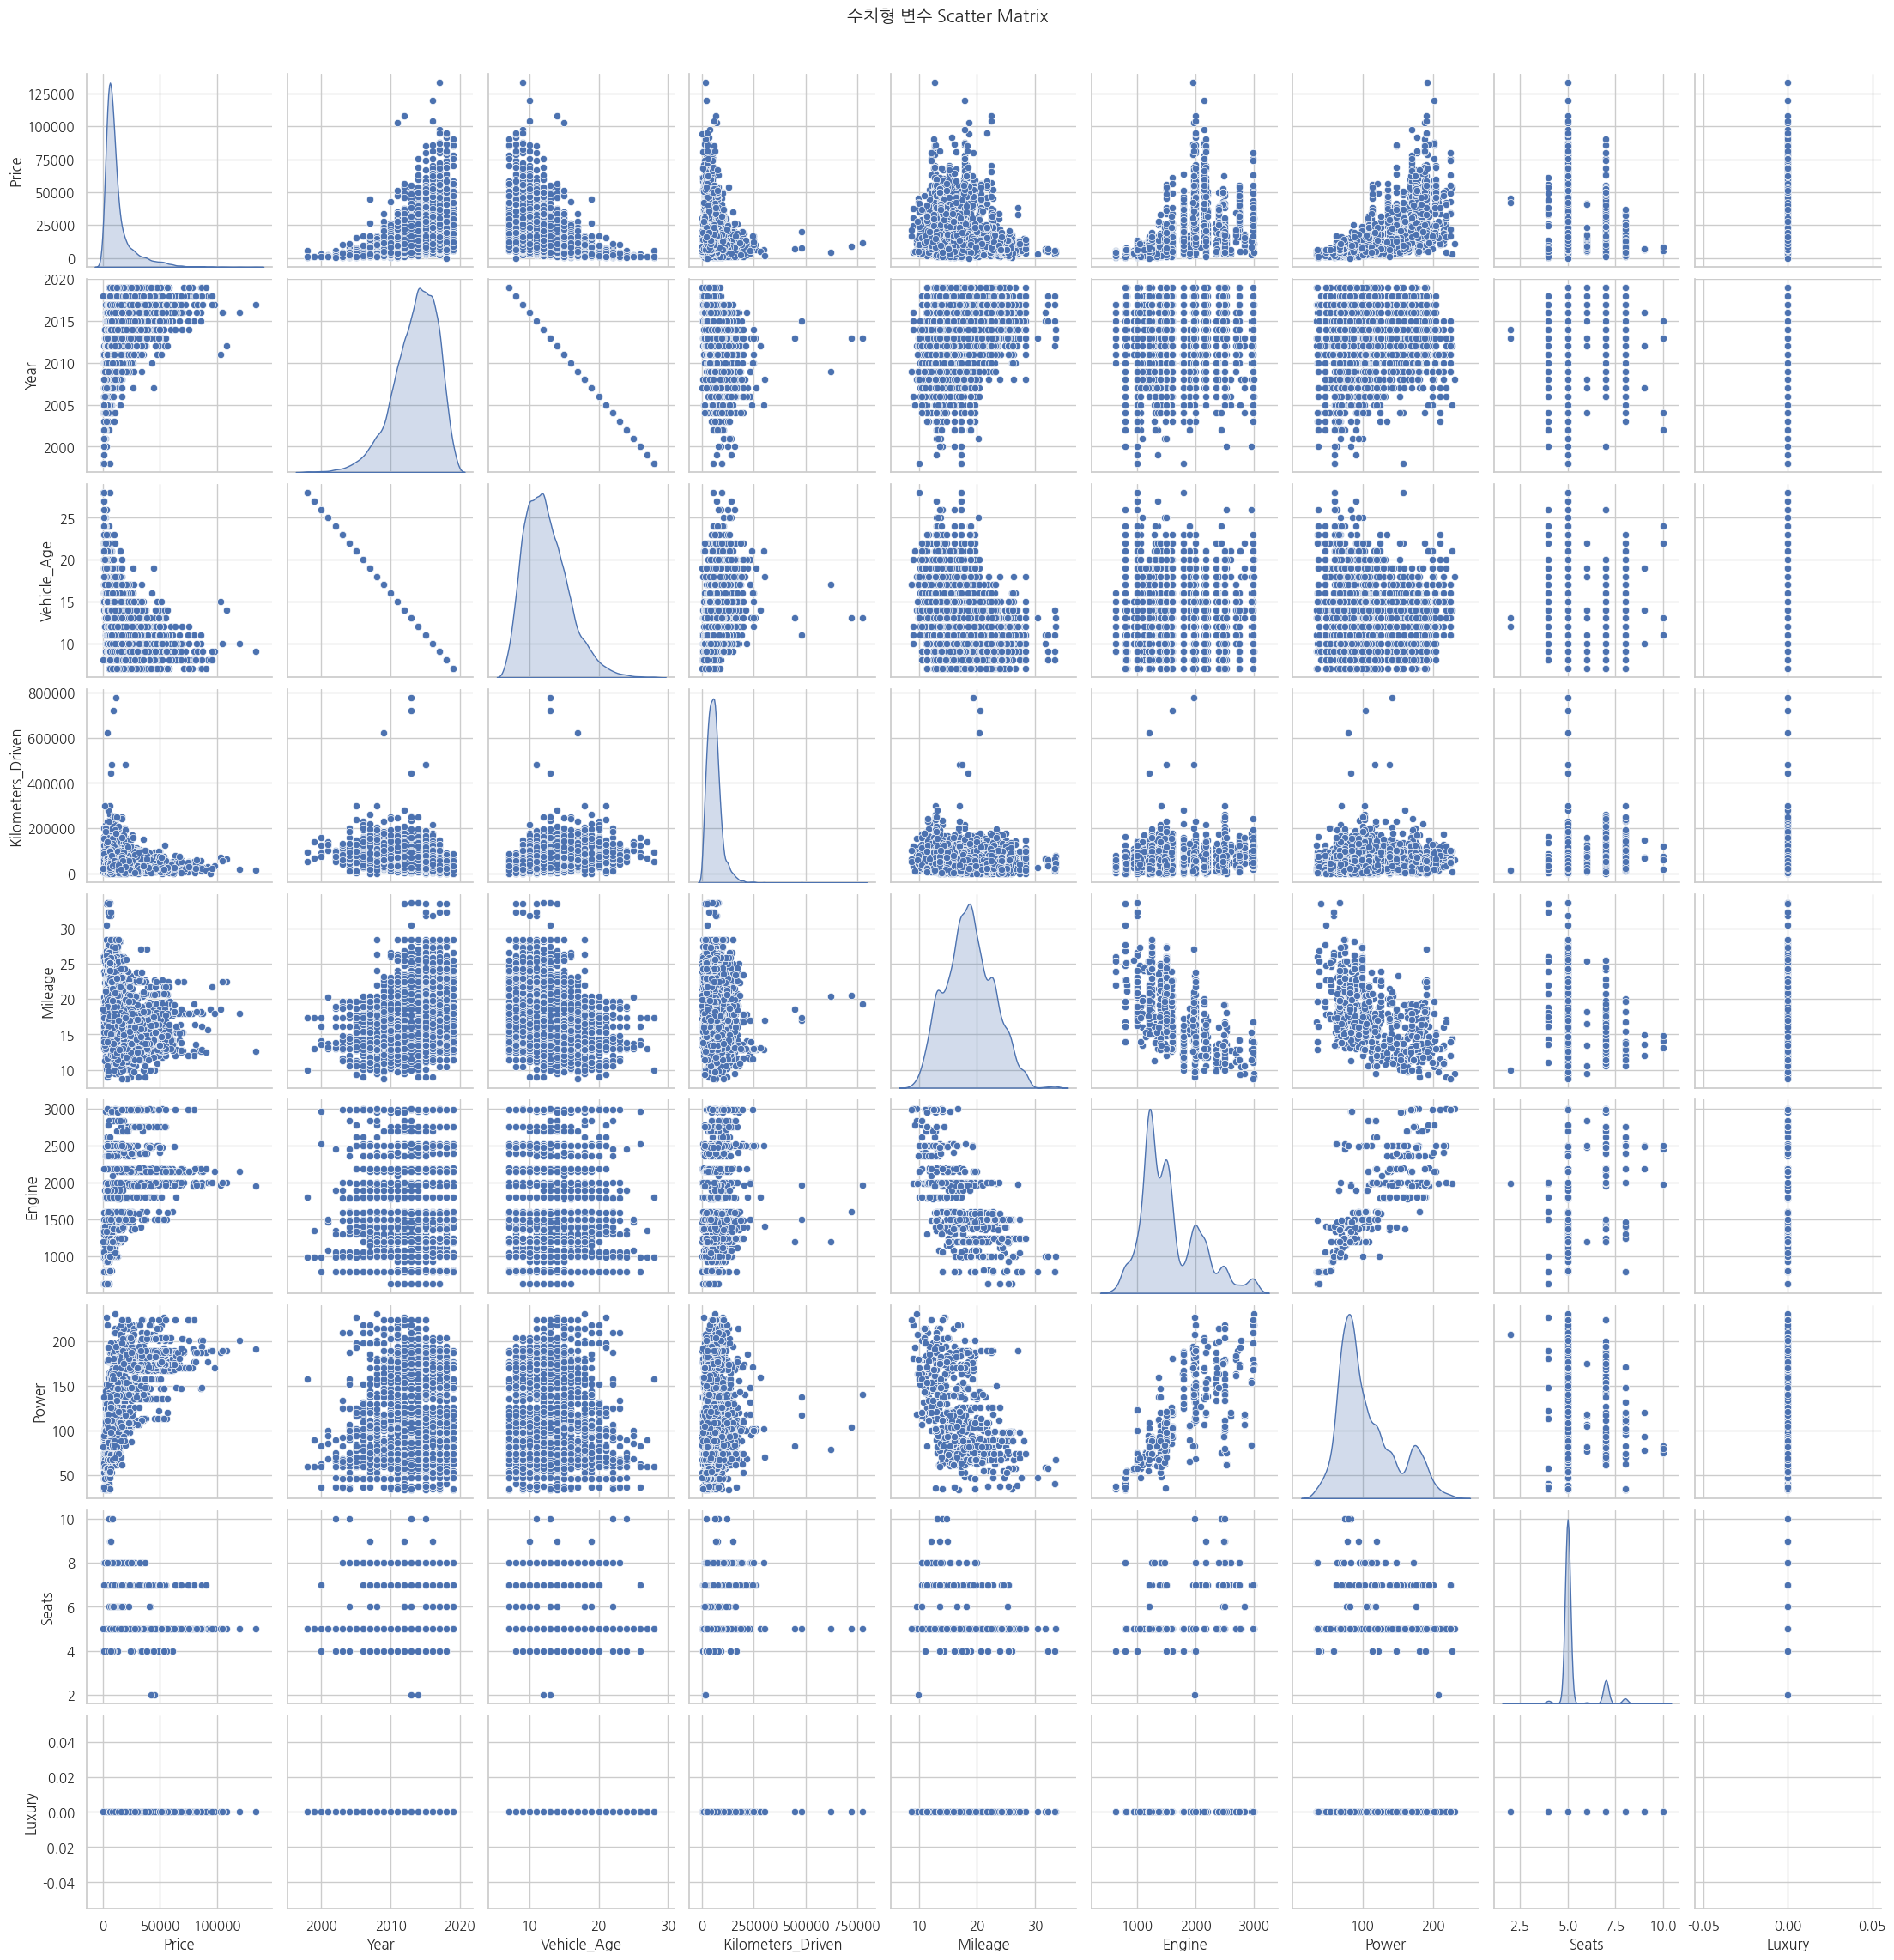

In [25]:
scatter_cols = [
    "Price",
    "Year",
    "Vehicle_Age",
    "Kilometers_Driven",
    "Mileage",
    "Engine",
    "Power",
    "Seats",
    "Luxury"
]

scatter_cols = [col for col in scatter_cols if col in df_model_no_outlier_removed.columns]

sns.pairplot(df_model_no_outlier_removed[scatter_cols].dropna(), diag_kind="kde")
plt.suptitle("수치형 변수 Scatter Matrix", y=1.02)
plt.show()

In [ ]:
num_features_for_scatter = [col for col in scatter_cols if col != "Price"]

plt.figure(figsize=(16, 12))

for i, col in enumerate(num_features_for_scatter, 1):
    plt.subplot(3, 3, i)
    sns.scatterplot(data=df_model_no_outlier_removed, x=col, y="Price", alpha=0.5)
    plt.title(f"{col} vs Price")

plt.tight_layout()
plt.show()

## 8. 통계적 가설검정

범주형 변수는 ANOVA로 `Price` 평균 차이가 유의미한지 확인합니다. 수치형 변수는 피어슨 상관계수를 계산하고 Heatmap으로 시각화합니다.

In [26]:
def anova_test_for_categorical(df, categorical_cols, target="Price", min_group_size=2):
    results = []

    for col in categorical_cols:
        if col not in df.columns:
            continue

        temp = df[[col, target]].dropna()
        groups = [
            group[target].values
            for _, group in temp.groupby(col)
            if len(group) >= min_group_size
        ]

        if len(groups) >= 2:
            f_stat, p_value = stats.f_oneway(*groups)

            results.append({
                "variable": col,
                "num_groups": temp[col].nunique(),
                "F_statistic": f_stat,
                "p_value": p_value,
                "significant_0.05": p_value < 0.05
            })

    return pd.DataFrame(results).sort_values("p_value")


categorical_cols_for_test = ["Brand", "Location", "Fuel_Type", "Transmission", "Owner_Type"]

anova_results = anova_test_for_categorical(
    df_model_no_outlier_removed,
    categorical_cols_for_test,
    target="Price"
)

display(anova_results)

,variable,num_groups,F_statistic,p_value,significant_0.05
0,Brand,26,344.637992,0.000000e+00,True
3,Transmission,2,2923.297114,0.000000e+00,True
2,Fuel_Type,5,208.188021,2.952279e-167,True
1,Location,11,38.517704,4.489029e-74,True
4,Owner_Type,4,34.004668,8.812539e-22,True


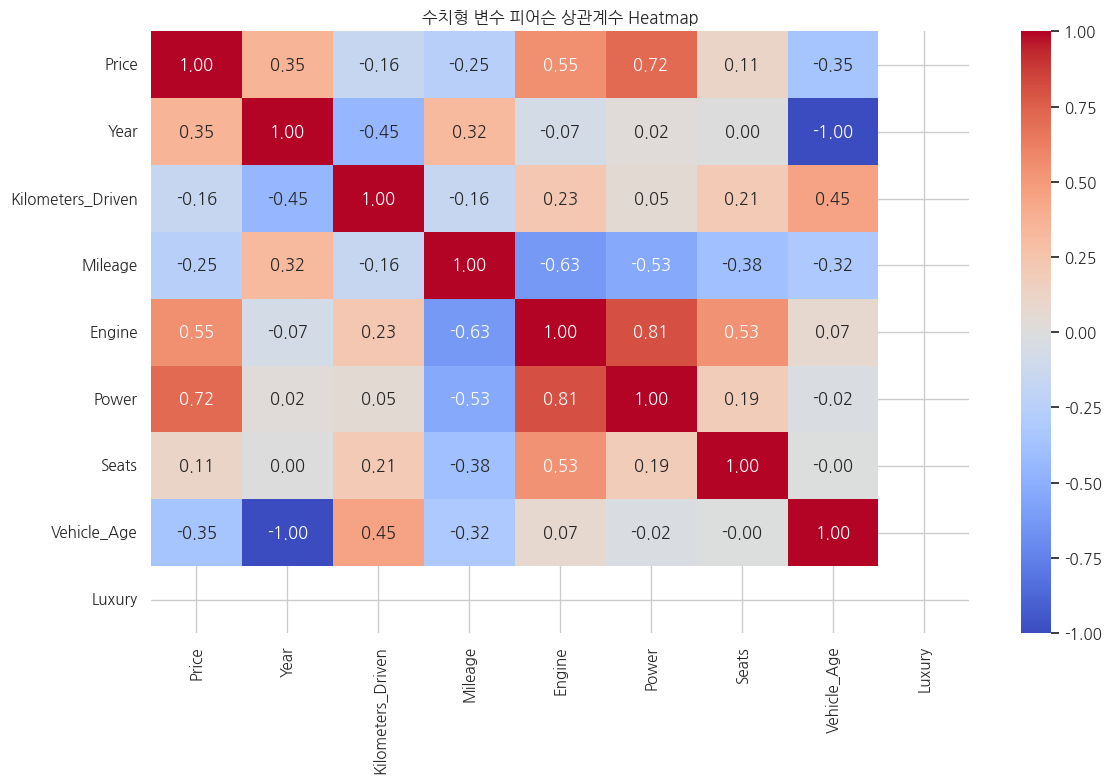

,Price
Price,1.000000
Power,0.716325
Engine,0.547527
Year,0.354772
Seats,0.109635
Kilometers_Driven,-0.156564
Mileage,-0.252070
Vehicle_Age,-0.354772
Luxury,NaN


In [27]:
numeric_df = df_model_no_outlier_removed.select_dtypes(include=np.number)

corr_matrix = numeric_df.corr(method="pearson")

plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("수치형 변수 피어슨 상관계수 Heatmap")
plt.tight_layout()
plt.show()

price_corr = corr_matrix["Price"].sort_values(ascending=False)
display(price_corr)

## 9. 다중공선성 확인: VIF

`Year`와 `Vehicle_Age`는 서로 거의 완전한 선형관계이므로 모델링에서는 둘 중 하나만 사용하는 것이 좋습니다.

In [28]:
def calculate_vif(df, numeric_features):
    X = df[numeric_features].copy()
    X = X.fillna(X.median(numeric_only=True))

    nunique = X.nunique()
    X = X.loc[:, nunique > 1]

    X_const = add_constant(X)

    vif_data = []
    for i, col in enumerate(X_const.columns):
        if col == "const":
            continue

        vif_data.append({
            "variable": col,
            "VIF": variance_inflation_factor(X_const.values, i)
        })

    return pd.DataFrame(vif_data).sort_values("VIF", ascending=False)


vif_features = [
    "Year",
    "Vehicle_Age",
    "Kilometers_Driven",
    "Mileage",
    "Engine",
    "Power",
    "Seats",
    "Luxury"
]

vif_features = [col for col in vif_features if col in df_model_no_outlier_removed.columns]

vif_result = calculate_vif(df_model_no_outlier_removed, vif_features)
display(vif_result)

,variable,VIF
0,Year,inf
1,Vehicle_Age,inf
4,Engine,5.642794
5,Power,4.018987
3,Mileage,2.013273
6,Seats,1.925831
2,Kilometers_Driven,1.410371


In [29]:
# ============================================================
# 듀얼 마켓 모델링 비활성화 안내
# ============================================================
# 이전 버전에서는 Normal / Luxury 시장을 분리해 각각 모델링했다.
# 하지만 현재 최종 방향은 Luxury 차량을 분석/모델링 데이터에서 제외하고,
# 일반 차량 데이터(df_model_no_outlier_removed)만으로 성능을 평가하는 것이다.
# 따라서 듀얼 마켓 모델링은 실행하지 않는다.

print("듀얼 마켓 모델링은 현재 최종 분석 방향과 달라 비활성화했습니다.")
print("모델링 대상 데이터: df_model_no_outlier_removed")
print("df_model_no_outlier_removed shape:", df_model_no_outlier_removed.shape)


듀얼 마켓 모델링은 현재 최종 분석 방향과 달라 비활성화했습니다.
모델링 대상 데이터: df_model_no_outlier_removed
df_model_no_outlier_removed shape: (5871, 15)


## 10. 모델링 및 성능 비교

학습용과 검증용 데이터로 분리한 뒤, 범주형 변수는 One-Hot Encoding을 적용합니다. 기본 모델인 Linear Regression과 트리 기반 모델인 Random Forest를 비교합니다.

In [30]:
# ============================================================
# 모델링 함수: log1p 타겟 학습 후 원단위 복원 평가
# [팀원 수정 및 피드백 반영]
# ============================================================

def rmse_score(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))


def prepare_features(df):
    """
    모델링에 사용할 컬럼을 정리합니다.
    Price는 타겟 변수이므로 X에서 제외합니다.
    Name은 원문 문자열이라 제거하고 Brand를 사용합니다.
    Year는 Vehicle_Age와 다중공선성이 크므로 제외합니다.

    Luxury == 1 차량은 이미 분석/모델링 데이터에서 제외되었습니다.
    따라서 Luxury 컬럼처럼 모든 행에서 값이 같은 상수 컬럼은 모델 입력에서 제외합니다.
    """
    df = df.copy()

    drop_cols = ["Price", "Name", "Year"]

    X = df.drop(columns=[col for col in drop_cols if col in df.columns])
    y = df["Price"]

    # Luxury처럼 모든 행에서 값이 같은 상수 컬럼은 예측 정보가 없으므로 제거한다.
    constant_cols = [col for col in X.columns if X[col].nunique(dropna=False) <= 1]
    if len(constant_cols) > 0:
        print("모델 입력에서 제외된 상수 컬럼:", constant_cols)
        X = X.drop(columns=constant_cols)

    return X, y


def train_and_evaluate_models(df, dataset_name="dataset"):
    """
    train/validation split 이후 학습 시점에만 y_train에 np.log1p를 적용합니다.
    예측값은 log_pred로 받은 뒤 np.expm1(log_pred)로 원래 Price 단위로 복원하고,
    원본 y_valid와 비교하여 MAE, RMSE, R²를 계산합니다.
    """

    print()
    print(f"[{dataset_name}] 모델링 입력 데이터 shape:", df.shape)

    X, y = prepare_features(df)

    numeric_features = X.select_dtypes(include=np.number).columns.tolist()
    categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

    print("X shape:", X.shape)
    print("y shape:", y.shape)
    print("수치형 변수:", numeric_features)
    print("범주형 변수:", categorical_features)

    X_train, X_valid, y_train, y_valid = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=RANDOM_STATE
    )

    print("Train shape:", X_train.shape, y_train.shape)
    print("Validation shape:", X_valid.shape, y_valid.shape)

    # 원본 Price는 변환하지 않고, 모델 fit 시점에만 로그 변환한다.
    y_train_log = np.log1p(y_train)

    linear_preprocess = ColumnTransformer(
        transformers=[
            ("num", Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]), numeric_features),

            ("cat", Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
            ]), categorical_features)
        ]
    )

    tree_preprocess = ColumnTransformer(
        transformers=[
            ("num", Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="median"))
            ]), numeric_features),

            ("cat", Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
            ]), categorical_features)
        ]
    )

    models = {
        "Linear Regression": Pipeline(steps=[
            ("preprocess", linear_preprocess),
            ("model", LinearRegression())
        ]),

        "Random Forest": Pipeline(steps=[
            ("preprocess", tree_preprocess),
            ("model", RandomForestRegressor(
                n_estimators=300,
                max_depth=None,
                min_samples_split=2,
                min_samples_leaf=1,
                random_state=RANDOM_STATE,
                n_jobs=-1
            ))
        ])
    }

    results = []

    for model_name, model in models.items():
        model.fit(X_train, y_train_log)

        log_pred = model.predict(X_valid)
        pred = np.expm1(log_pred)
        pred = np.maximum(pred, 0)

        results.append({
            "데이터셋": dataset_name,
            "모델명": model_name,
            "MAE": mean_absolute_error(y_valid, pred),
            "RMSE": rmse_score(y_valid, pred),
            "R²": r2_score(y_valid, pred)
        })

    return pd.DataFrame(results)


In [31]:
model_score_table = train_and_evaluate_models(
    df_model_no_outlier_removed,
    dataset_name="Luxury 제외 일반 차량 데이터"
)

score_table_sorted = (
    model_score_table
    .sort_values(by=["R²", "RMSE"], ascending=[False, True])
    .reset_index(drop=True)
)

score_table_sorted.index = score_table_sorted.index + 1

display(score_table_sorted)



[Luxury 제외 일반 차량 데이터] 모델링 입력 데이터 shape: (5871, 15)
모델 입력에서 제외된 상수 컬럼: ['Luxury']
X shape: (5871, 11)
y shape: (5871,)
수치형 변수: ['Kilometers_Driven', 'Mileage', 'Engine', 'Power', 'Seats', 'Vehicle_Age']
범주형 변수: ['Location', 'Fuel_Type', 'Transmission', 'Owner_Type', 'Brand']
Train shape: (4696, 11) (4696,)
Validation shape: (1175, 11) (1175,)


,데이터셋,모델명,MAE,RMSE,R²
1,Luxury 제외 일반 차량 데이터,Random Forest,2112.133548,4579.955707,0.876184
2,Luxury 제외 일반 차량 데이터,Linear Regression,2377.239775,4587.895964,0.875754


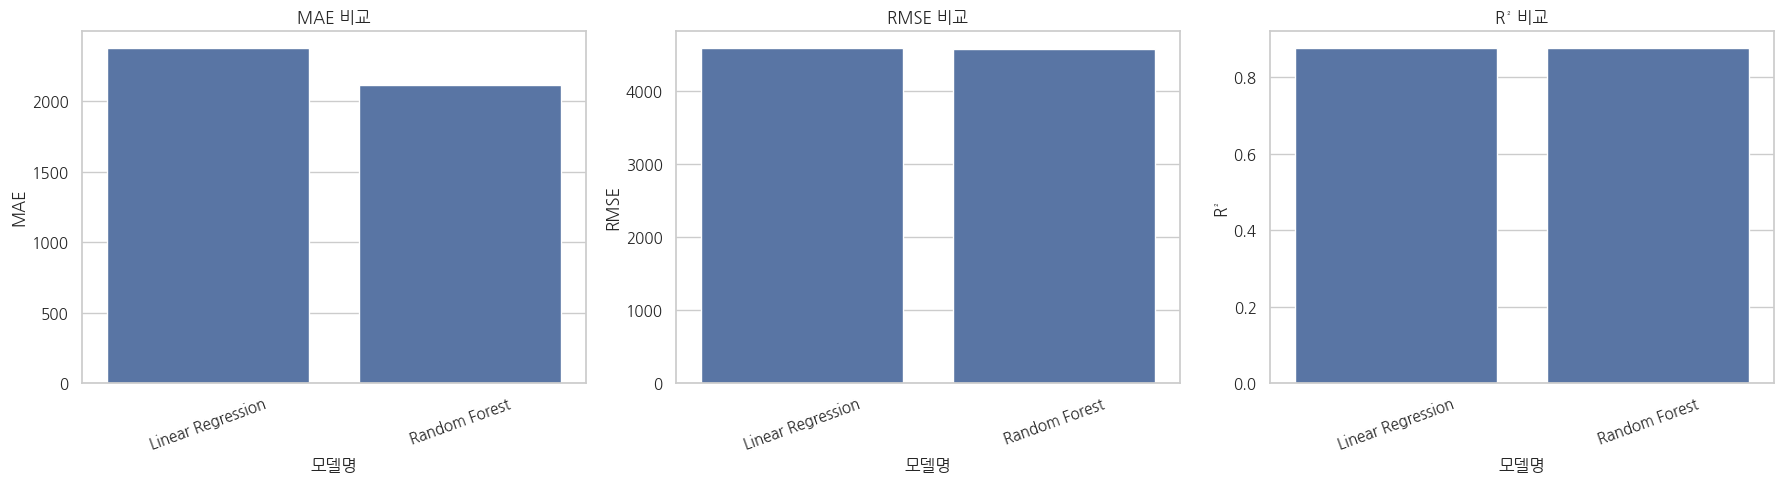

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(data=model_score_table, x="모델명", y="MAE", ax=axes[0])
axes[0].set_title("MAE 비교")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(data=model_score_table, x="모델명", y="RMSE", ax=axes[1])
axes[1].set_title("RMSE 비교")
axes[1].tick_params(axis="x", rotation=20)

sns.barplot(data=model_score_table, x="모델명", y="R²", ax=axes[2])
axes[2].set_title("R² 비교")
axes[2].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()


## 11. 최종 모델 선정 및 결론 정리

이번 프로젝트는 새로운 가격 미기재 데이터를 예측하는 것이 아니라, `Price`가 존재하는 데이터에서 train/validation 성능을 비교해 더 적절한 모델과 전처리 전략을 선정하는 것이 목표입니다.

In [33]:
# ============================================================
# 최종 모델 후보 선정
# ============================================================

best_row = score_table_sorted.iloc[0]

print("Validation 성능 기준 최종 후보")
display(best_row)

print()
print("해석 가이드")
print("- MAE, RMSE는 낮을수록 좋습니다.")
print("- R²는 높을수록 좋습니다.")
print("- Price는 원본 단위를 유지했고, 모델 학습 시점에만 log1p를 적용했습니다.")
print("- 성능 평가는 expm1로 원래 Price 단위로 복원한 예측값 기준입니다.")
print("- Luxury 차량은 df_luxury_cars로 별도 분리했고, 모델링 데이터에서는 제외했습니다.")


Validation 성능 기준 최종 후보


,1
데이터셋,Luxury 제외 일반 차량 데이터
모델명,Random Forest
MAE,2112.133548
RMSE,4579.955707
R²,0.876184



해석 가이드
- MAE, RMSE는 낮을수록 좋습니다.
- R²는 높을수록 좋습니다.
- Price는 원본 단위를 유지했고, 모델 학습 시점에만 log1p를 적용했습니다.
- 성능 평가는 expm1로 원래 Price 단위로 복원한 예측값 기준입니다.
- Luxury 차량은 df_luxury_cars로 별도 분리했고, 모델링 데이터에서는 제외했습니다.


### 결론 작성 예시

- `Price` 원본 값은 EDA와 통계검정 단계에서 그대로 유지하였다.
- 모델 학습 시점에만 `log1p(Price)`를 적용하고, 예측 후 `expm1`로 복원하여 원래 단위 기준 MAE, RMSE, R²를 계산하였다.
- `Kilometers_Driven >= 6,000,000`, `Mileage == 0`, `Seats == 0`은 도메인상 비정상 입력 가능성이 높아 제거하였다.
- IQR 기준 이상치는 탐색용으로만 확인하고, IQR 기준 행 삭제는 수행하지 않았다.
- `Engine`과 `Power`의 75% 분위수를 모두 만족하는 차량을 `Luxury = 1`로 정의하였다.
- `Luxury = 1` 차량은 `df_luxury_cars`로 별도 분리하고, 분석/모델링용 데이터 `df_model_no_outlier_removed`에서는 제외하였다.
- 최종 모델은 Luxury 차량을 제외한 일반 차량 데이터의 Validation 성능표에서 MAE, RMSE, R²를 종합적으로 비교해 선정한다.
